In [3]:
import sys
import torch
import timm

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)
print("MPS available:", torch.backends.mps.is_available())

Python: 3.11.17 (main, Oct  1 2026, 00:48:48) [Clang 17.0.0 (clang-1700.6.4.2)]
PyTorch: 2.14.1
timm: 1.0.30
MPS available: True


# COVID-19 CT Scan Classification Using EfficientNet-B3

This project uses a pretrained EfficientNet-B3 convolutional neural network to classify CT scan images into COVID and non-COVID categories.

The workflow includes dataset preparation, preprocessing and augmentation, stratified train-validation splitting, model training, validation, model saving, and image-level inference.

In [ ]:
#importing dependencies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sn
import os, shutil, random

## Load the Dataset

### Subtask:
Download and locate the SARS-CoV-2 CT scan dataset using KaggleHub.

**Reasoning:**
Download the dataset locally and identify the COVID and non-COVID image directories for model training and validation.

In [26]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "plameneduardo/sarscov2-ctscan-dataset"
)

print("Dataset downloaded to:")
print(dataset_path)

print("\nContents:")
print(os.listdir(dataset_path))

Dataset downloaded to:
/Users/anushka/.cache/kagglehub/datasets/plameneduardo/sarscov2-ctscan-dataset/versions/2

Contents:
['non-COVID', 'COVID']


In [27]:
import os

covid_dir = os.path.join(dataset_path, "COVID")
non_covid_dir = os.path.join(dataset_path, "non-COVID")

print("COVID folder:", covid_dir)
print("non-COVID folder:", non_covid_dir)

print("COVID images:", len(os.listdir(covid_dir)))
print("non-COVID images:", len(os.listdir(non_covid_dir)))

COVID folder: /Users/anushka/.cache/kagglehub/datasets/plameneduardo/sarscov2-ctscan-dataset/versions/2/COVID
non-COVID folder: /Users/anushka/.cache/kagglehub/datasets/plameneduardo/sarscov2-ctscan-dataset/versions/2/non-COVID
COVID images: 1252
non-COVID images: 1229


In [ ]:
import os

image_paths = []
labels = []

# COVID = 1
for filename in os.listdir(covid_dir):
    file_path = os.path.join(covid_dir, filename)
    if os.path.isfile(file_path):
        image_paths.append(file_path)
        labels.append(1)

# non-COVID = 0
for filename in os.listdir(non_covid_dir):
    file_path = os.path.join(non_covid_dir, filename)
    if os.path.isfile(file_path):
        image_paths.append(file_path)
        labels.append(0)

print("Total images:", len(image_paths))
print("COVID:", labels.count(1))
print("non-COVID:", labels.count(0))

Total images: 2481
COVID: 1252
non-COVID: 1229


In [ ]:
import torchvision.transforms as transforms

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Training and validation transforms defined.")

Training and validation transforms defined.


MARKDOWN:

## Create a custom dataset class

### Subtask:
Create a PyTorch Dataset to handle loading images and applying transformations.




*Reasoning*:
Define a custom PyTorch Dataset class to load images and apply transformations.

In [10]:
from torch.utils.data import Dataset
from PIL import Image

class CTScanDataset(Dataset):
    def __init__(self, image_paths, labels, transform=None):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        image = Image.open(img_path).convert('RGB') # Ensure image is in RGB format

        if self.transform:
            image = self.transform(image)

        return image, label

MARKDOWN:

## Split the dataset

### Subtask:
Split the dataset into training and validation sets.

In [11]:
from sklearn.model_selection import train_test_split

train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Training set size:", len(train_paths))
print("Validation set size:", len(val_paths))

print("Training COVID:", train_labels.count(1))
print("Training non-COVID:", train_labels.count(0))

print("Validation COVID:", val_labels.count(1))
print("Validation non-COVID:", val_labels.count(0))

Training set size: 1984
Validation set size: 497
Training COVID: 1001
Training non-COVID: 983
Validation COVID: 251
Validation non-COVID: 246


MARKDOWN:


## Create data loaders

### Subtask:
Create PyTorch `DataLoader`s for the training and validation sets.

In [12]:
from torch.utils.data import DataLoader

# Create dataset instances
train_dataset = CTScanDataset(
    train_paths,
    train_labels,
    transform=train_transform
)

val_dataset = CTScanDataset(
    val_paths,
    val_labels,
    transform=val_transform
)

# Start with a smaller batch size for the Mac
batch_size = 8

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Training samples: 1984
Validation samples: 497
Training batches: 248
Validation batches: 63


## Define the EfficientNet-B3 Model

### Subtask:
Define a pretrained EfficientNet-B3 model for binary classification using the timm library.

**Reasoning:**
Use a pretrained EfficientNet-B3 backbone and configure its classification layer for the two CT scan classes: COVID and non-COVID.

In [17]:
import timm
import torch

# Select the best available device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

# Create pretrained EfficientNet-B3 for binary classification
model = timm.create_model(
    "efficientnet_b3",
    pretrained=True,
    num_classes=2
)

model = model.to(device)

print("Model created successfully.")

Using device: mps
Model created successfully.


## Define the Loss Function and Optimizer

### Subtask:
Set up the loss function and optimizer for training the EfficientNet-B3 model.

**Reasoning:**
Use CrossEntropyLoss for the two-class classification task and AdamW with a learning rate of 0.001 for optimization.

In [18]:
import torch.nn as nn
import torch.optim as optim

# Loss function for binary classification
criterion = nn.CrossEntropyLoss()

# AdamW optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer defined.")

Loss function and optimizer defined.


## Train the EfficientNet-B3 Model

### Subtask:
Train the EfficientNet-B3 model for 50 epochs.

**Reasoning:**
Train the model using forward propagation, loss calculation, backpropagation, and AdamW optimization while tracking training loss and accuracy.

In [19]:
import torch
import time

# full training
num_epochs = 50

print(f"Training EfficientNet-B3 on device: {device}")

for epoch in range(num_epochs):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    start_time = time.time()

    for images, labels_batch in train_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels_batch)

        # Backward pass
        loss.backward()

        # Update weights
        optimizer.step()

        # Track statistics
        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels_batch.size(0)
        correct += (predicted == labels_batch).sum().item()

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = 100 * correct / total
    elapsed = time.time() - start_time

    print(
        f"Epoch [{epoch + 1}/{num_epochs}] "
        f"Loss: {epoch_loss:.4f} "
        f"Accuracy: {epoch_accuracy:.2f}% "
        f"Time: {elapsed:.1f}s"
    )

Training EfficientNet-B3 on device: mps
Epoch [1/50] Loss: 1.0954 Accuracy: 75.00% Time: 84.8s
Epoch [2/50] Loss: 0.4266 Accuracy: 81.91% Time: 84.5s
Epoch [3/50] Loss: 0.3806 Accuracy: 83.87% Time: 85.4s
Epoch [4/50] Loss: 0.3308 Accuracy: 85.89% Time: 105.1s
Epoch [5/50] Loss: 0.3149 Accuracy: 86.49% Time: 100.7s
Epoch [6/50] Loss: 0.2855 Accuracy: 88.05% Time: 102.0s
Epoch [7/50] Loss: 0.3023 Accuracy: 88.41% Time: 102.4s
Epoch [8/50] Loss: 0.2923 Accuracy: 88.05% Time: 102.6s
Epoch [9/50] Loss: 0.2816 Accuracy: 87.85% Time: 94.8s
Epoch [10/50] Loss: 0.2441 Accuracy: 89.62% Time: 99.3s
Epoch [11/50] Loss: 0.2591 Accuracy: 89.26% Time: 102.4s
Epoch [12/50] Loss: 0.2476 Accuracy: 89.72% Time: 99.2s
Epoch [13/50] Loss: 0.2515 Accuracy: 89.57% Time: 100.2s
Epoch [14/50] Loss: 0.2307 Accuracy: 90.22% Time: 102.6s
Epoch [15/50] Loss: 0.2162 Accuracy: 91.18% Time: 100.9s
Epoch [16/50] Loss: 0.2773 Accuracy: 88.61% Time: 101.1s
Epoch [17/50] Loss: 0.2574 Accuracy: 89.57% Time: 103.0s
Epoch 

## Evaluate Model Performance

### Subtask:
Evaluate the trained EfficientNet-B3 model on the validation dataset.

**Reasoning:**
Calculate standard classification metrics including accuracy, precision, recall, F1-score, ROC-AUC, and the confusion matrix to assess validation performance.

In [21]:
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

with torch.no_grad():
    for images, labels_batch in val_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        outputs = model(images)

        # Probability of COVID class (class 1)
        probabilities = torch.softmax(outputs, dim=1)[:, 1]

        # Predicted class
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels_batch.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

# Convert to NumPy arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)

# Calculate metrics
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

roc_auc = roc_auc_score(
    all_labels,
    all_probabilities
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("===== VALIDATION RESULTS =====")
print(f"Accuracy:  {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nConfusion Matrix:")
print(cm)


===== VALIDATION RESULTS =====
Accuracy:  0.9718 (97.18%)
Precision: 0.9611
Recall:    0.9841
F1 Score:  0.9724
ROC-AUC:   0.9967

Confusion Matrix:
[[236  10]
 [  4 247]]


## Save the Trained Model

### Subtask:
Save the trained EfficientNet-B3 model weights locally for later use.

**Reasoning:**
Save the model's state dictionary so that the trained model can be reloaded for inference without retraining.

In [22]:
import os
import torch

# Create a local folder for model weights
os.makedirs("models", exist_ok=True)

# Save the final 50-epoch model
model_path = "models/efficientnet_b3_sarscov2_model.pth"

torch.save(model.state_dict(), model_path)

print(f"Model saved successfully to: {model_path}")

Model saved successfully to: models/efficientnet_b3_sarscov2_model.pth


## Load the Saved Model

### Subtask:
Reload the trained EfficientNet-B3 model from the saved weights.

**Reasoning:**
Reconstruct the EfficientNet-B3 architecture and load the saved state dictionary to verify that the trained model can be restored for inference.

In [24]:

import torch
import timm

# Create the same EfficientNet-B3 architecture
loaded_model = timm.create_model(
    "efficientnet_b3",
    pretrained=False,
    num_classes=2
)

# Use the Mac's available device
loaded_model = loaded_model.to(device)

# Load the trained weights saved locally
model_save_path = "models/efficientnet_b3_sarscov2_model.pth"

loaded_model.load_state_dict(
    torch.load(
        model_save_path,
        map_location=device
    )
)

# Evaluation mode
loaded_model.eval()

print(f"EfficientNet-B3 model loaded from: {model_save_path}")

EfficientNet-B3 model loaded from: models/efficientnet_b3_sarscov2_model.pth


## Perform Image-Level Inference

### Subtask:
Use the trained EfficientNet-B3 model to classify an individual CT scan image.

**Reasoning:**
Preprocess a CT scan using the same validation preprocessing pipeline and use the trained model to predict whether the image belongs to the COVID or non-COVID class, along with the prediction confidence.

Matplotlib is building the font cache; this may take a moment.


Image used for prediction:
/Users/anushka/.cache/kagglehub/datasets/plameneduardo/sarscov2-ctscan-dataset/versions/2/non-COVID/Non-Covid (208).png

Actual class: non-COVID

Predicted class: non-COVID
Prediction confidence: 83.60%

Prediction probabilities:
  non-COVID: 0.8360
  COVID: 0.1640


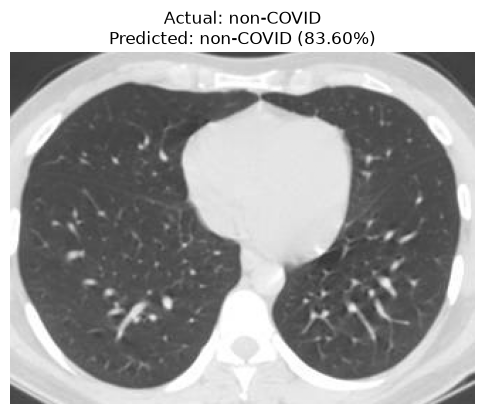

In [25]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt
import random
import os

# Prediction preprocessing
preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Class mapping
class_names = ['non-COVID', 'COVID']


def predict_image(image_path, model, device, class_names):
    """
    Predict whether a CT scan is COVID or non-COVID.
    """

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Preprocess
    input_tensor = preprocess(image)
    input_batch = input_tensor.unsqueeze(0).to(device)

    # Inference
    model.eval()

    with torch.no_grad():
        output = model(input_batch)
        probabilities = torch.softmax(output, dim=1)[0]

    predicted_class_idx = torch.argmax(probabilities).item()
    predicted_class_name = class_names[predicted_class_idx]
    predicted_probability = probabilities[predicted_class_idx].item()

    return (
        predicted_class_idx,
        predicted_class_name,
        predicted_probability,
        probabilities.cpu().numpy()
    )


# --------------------------------------------------
# DEMONSTRATION USING A RANDOM VALIDATION IMAGE
# --------------------------------------------------

# Pick a random validation image
sample_index = random.randrange(len(val_paths))
sample_image_path = val_paths[sample_index]
actual_label = val_labels[sample_index]

print("Image used for prediction:")
print(sample_image_path)

print("\nActual class:", class_names[actual_label])


# Make prediction using the SAVED model
predicted_idx, predicted_name, predicted_probability, probabilities = predict_image(
    sample_image_path,
    loaded_model,
    device,
    class_names
)

print("\nPredicted class:", predicted_name)
print(f"Prediction confidence: {predicted_probability:.2%}")

print("\nPrediction probabilities:")
for i, prob in enumerate(probabilities):
    print(f"  {class_names[i]}: {prob:.4f}")


# Display image
img = Image.open(sample_image_path)

plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title(
    f"Actual: {class_names[actual_label]}\n"
    f"Predicted: {predicted_name} ({predicted_probability:.2%})"
)
plt.axis("off")
plt.show()

## Summary

### Key Findings

* A pretrained EfficientNet-B3 model was configured for binary classification of COVID and non-COVID CT scan images.
* The SARS-CoV-2 CT scan dataset was downloaded using KaggleHub and divided into training and validation sets using stratified sampling.
* Image preprocessing included resizing, normalization, and training-time augmentation using random cropping, horizontal flipping, and rotation.
* The model was trained for 50 epochs using CrossEntropyLoss and the AdamW optimizer.
* On the validation set, the model achieved 97.18% accuracy, 96.11% precision, 98.41% recall, 97.24% F1-score, and 99.67% ROC-AUC.
* The trained model weights were saved locally and successfully reloaded for image-level inference.

